# Portfolio replication variants: HRP-ordered set encoding, and a hybrid with QP weights

This notebook builds on [pymoo_rep.ipynb](pymoo_rep.ipynb), the pymoo replication of Hidalgo-Marín, Nebro & García-Nieto (2026), referred to below as the **replica**. It keeps the same 12 instances, the three algorithms (MOEA/D, SMS-EMOA, NSGA-II), the Table 3 settings, the evaluation budgets and the seeds. Run `pymoo_rep.ipynb` first: this notebook reuses its downloaded data and its saved runs.

| | Asset selection | Two genes point to the same asset | Weights |
|---|---|---|---|
| **Replica** | k real-valued pointers, asset $=\lfloor xN \rfloor$ | move to the next asset *index* (linear probing) | k real genes: SBX + polynomial mutation, then normalised and bounded |
| **HRP set** | set-based: k asset ids, uniform slot crossover, swap mutation | move to the next free asset in the **HRP dendrogram's leaf order** | as in the replica |
| **Hybrid** | as HRP set | as HRP set | **solved exactly** for the chosen assets (the MIQP with its binary part fixed is a QP). One extra gene sets the risk–return trade-off |

1. Settings and data
2. HRP quasi-diagonalisation (leaf order)
3. HRP set variant: run, then compare with the replica
4. Hybrid variant: run, then compare all three
5. Summary

## 1. Settings and data

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import quadprog
from joblib import Parallel, delayed
from scipy import stats
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.optimize import minimize as scipy_minimize
from scipy.spatial.distance import squareform

from pymoo.algorithms.moo.moead import MOEAD
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.moo.sms import SMSEMOA
from pymoo.core.crossover import Crossover
from pymoo.core.mutation import Mutation
from pymoo.core.problem import Problem
from pymoo.core.repair import Repair
from pymoo.core.sampling import Sampling
from pymoo.decomposition.pbi import PBI
from pymoo.indicators.hv import HV
from pymoo.indicators.igd_plus import IGDPlus
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.optimize import minimize
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting
from pymoo.util.ref_dirs import get_reference_directions

# --- the same experiment as pymoo_rep.ipynb (these must match its saved runs) ---------------
INSTANCES = [
    "NYSE_5_100", "NASDAQ_5_100", "OTC_5_100", "AMEX_5_100", "ARCA_5_100", "BATS_5_100", "ALL_5_100",
    "ALL_20_100", "ALL_20_500", "ALL_20_1000", "ALL_20_3000", "ALL_20_6000",
]
ALGORITHMS = ["MOEA/D", "SMS-EMOA", "NSGA-II"]
N_RUNS = 10
POP_SIZE = 100
BASE_EVALS = 50_000
EVAL_MULTIPLIER = {"ALL_20_500": 2, "ALL_20_1000": 3, "ALL_20_3000": 4, "ALL_20_6000": 5}
EVAL_SCALE = 1.0
SEED = 12345
RISK_FREE = 0.0697
TRADING_DAYS = 250
N_JOBS = -1

# --- new in this notebook ----------------------------------------------------------------------
LINKAGE = "single"          # linkage of the HRP clustering (López de Prado's HRP uses single linkage)
LOG10_GAMMA = (-2.0, 4.0)   # hybrid: risk aversion gamma = 10**(-2 + 6 t) for its trade-off gene t in [0, 1]


def n_evals(instance):
    return int(BASE_EVALS * EVAL_MULTIPLIER.get(instance, 1) * EVAL_SCALE)


ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW, PROCESSED, FIGURES = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

VARIANT_LABELS = {
    "replica": "Replica (pointer encoding, linear probing)",
    "hrp": "HRP set (set-based encoding, HRP leaf-order repair)",
    "hybrid": "Hybrid (HRP set for the assets, QP-optimal weights)",
}
SHORT = {"replica": "replica", "hrp": "HRP set", "hybrid": "hybrid"}
LINE_STYLE = {
    "replica": dict(color="#8f8e88", lw=3.5, solid_capstyle="round", zorder=1),
    "hrp": dict(color="black", lw=1.1, zorder=2),
    "hybrid": dict(color="#eb6834", lw=1.3, zorder=3),
}
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.spines.top": False, "axes.spines.right": False,
})

In [2]:
def raw_path(instance, kind):
    return RAW / f"{instance}_{kind}.csv"


def cache_path(variant, instance, algorithm):
    slug = algorithm.replace("/", "").replace("-", "")
    prefix = "pymoo" if variant == "replica" else f"pymoo-{variant}"
    return PROCESSED / f"{prefix}_{instance}_{slug}_{n_evals(instance)}evals.csv"


def finished_runs(variant, instance, algorithm):
    path = cache_path(variant, instance, algorithm)
    return set(pd.read_csv(path, usecols=["run"])["run"]) if path.exists() else set()


def load_instance(instance, with_cov=True):
    mu = pd.read_csv(raw_path(instance, "mean_return"), index_col=0).iloc[:, 0]
    cov = None
    if with_cov:
        cov_df = pd.read_csv(raw_path(instance, "covariance"), index_col=0)
        assert list(cov_df.index) == list(cov_df.columns) == list(mu.index), "assets out of order"
        cov = cov_df.to_numpy()
    assets = [s.rsplit("\\", 1)[-1].removeprefix("Day_") for s in mu.index]
    return {"k": int(instance.split("_")[1]), "mu": mu.to_numpy(), "cov": cov, "assets": assets}


def pick(instance):
    return instance if instance in INSTANCES else INSTANCES[-1]


missing = [p.name for inst in INSTANCES for p in (raw_path(inst, "mean_return"), raw_path(inst, "covariance"))
           if not p.exists()]
missing += [cache_path("replica", inst, alg).name for inst in INSTANCES for alg in ALGORITHMS
            if len(finished_runs("replica", inst, alg)) < N_RUNS]
if missing:
    raise FileNotFoundError("Run pymoo_rep.ipynb first, with the same INSTANCES, N_RUNS and EVAL_SCALE. "
                            f"Missing or incomplete: {missing[:4]}{' ...' if len(missing) > 4 else ''}")
print(f"data and {len(INSTANCES) * len(ALGORITHMS) * N_RUNS} replica runs found")

data and 360 replica runs found


## 2. HRP quasi-diagonalisation

Hierarchical Risk Parity (López de Prado, 2016) starts by clustering assets on the correlation distance

$$d_{ij} = \sqrt{\tfrac{1}{2}\,(1-\rho_{ij})},$$

which is 0 for perfectly correlated assets, $1/\sqrt{2}$ for uncorrelated ones and 1 for perfectly anti-correlated ones. Reading the dendrogram's leaves from left to right gives an ordering of the assets in which similar assets sit next to each other. Reordering the correlation matrix this way makes it *quasi-diagonal*, with correlated blocks along the diagonal.

That ordering is used here to resolve collisions. When two genes point to the same asset, the second one moves to the next free asset in leaf order: its neighbour in the dendrogram, an asset from the same or the closest cluster. The repaired portfolio therefore changes as little as possible in risk terms. In the replica, "the next asset" is simply the next index in the return-sorted universe, which has nothing to do with the asset's correlations.

Each instance's leaf order is computed once from its covariance matrix (single linkage, as in HRP) and cached in `data/processed/`. The table measures how similar the replacement asset is under each rule: the average correlation between every asset and the asset a collision would move it to. The leaf-order neighbour is more correlated on every instance. With single linkage the gain is moderate, because single linkage tends to chain clusters together.

In [3]:
def hrp_leaf_order(cov, method=LINKAGE):
    """Leaf order of a hierarchical clustering on d_ij = sqrt((1 - rho_ij) / 2): HRP's quasi-diagonalisation."""
    sd = np.sqrt(np.diag(cov))
    corr = np.clip(cov / np.outer(sd, sd), -1.0, 1.0)
    dist = np.sqrt(0.5 * (1.0 - corr))
    np.fill_diagonal(dist, 0.0)
    return leaves_list(linkage(squareform(dist, checks=False), method=method))


def leaf_order(instance, cov=None):
    path = PROCESSED / f"hrp_leaf_order_{instance}_{LINKAGE}.csv"
    if path.exists():
        return np.loadtxt(path, dtype=int)
    order = hrp_leaf_order(load_instance(instance)["cov"] if cov is None else cov)
    np.savetxt(path, order, fmt="%d")
    return order


def next_asset_correlation(cov, sequence):
    """Correlation between each asset and the one after it in `sequence` (wrapping around)."""
    sd = np.sqrt(np.diag(cov))
    nxt = np.roll(sequence, -1)
    return cov[sequence, nxt] / (sd[sequence] * sd[nxt])


rows = []
for inst in INSTANCES:
    cov = load_instance(inst)["cov"]
    order = leaf_order(inst, cov)
    rows.append({"instance": inst,
                 "replica: next index": next_asset_correlation(cov, np.arange(len(cov))).mean(),
                 "HRP: next in leaf order": next_asset_correlation(cov, order).mean()})
    del cov
pd.DataFrame(rows).set_index("instance").style.format("{:.3f}") \
    .set_caption("Mean correlation between an asset and the asset a collision moves it to")

,replica: next index,HRP: next in leaf order
instance,,
NYSE_5_100,0.400,0.476
NASDAQ_5_100,0.359,0.403
OTC_5_100,0.303,0.353
AMEX_5_100,0.155,0.232
ARCA_5_100,0.448,0.510
BATS_5_100,0.465,0.516
ALL_5_100,0.519,0.547
ALL_20_100,0.519,0.547
ALL_20_500,0.499,0.547


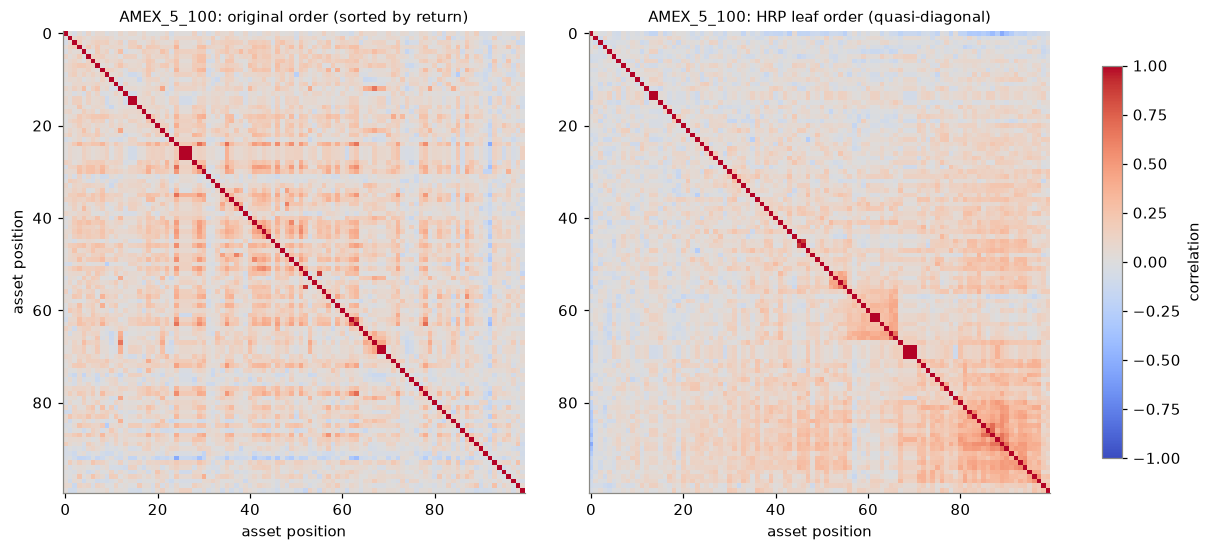

In [4]:
inst = pick("AMEX_5_100")
cov = load_instance(inst)["cov"]
sd = np.sqrt(np.diag(cov))
corr = cov / np.outer(sd, sd)
order = leaf_order(inst, cov)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.9), constrained_layout=True)
for ax, (title, idx) in zip(axes, [("original order (sorted by return)", np.arange(len(corr))),
                                   ("HRP leaf order (quasi-diagonal)", order)]):
    im = ax.imshow(corr[np.ix_(idx, idx)], cmap="coolwarm", vmin=-1, vmax=1, interpolation="nearest")
    ax.set_title(f"{inst}: {title}", fontsize=10)
    ax.set_xlabel("asset position")
    ax.grid(False)
axes[0].set_ylabel("asset position")
fig.colorbar(im, ax=axes, shrink=0.85, label="correlation")
fig.savefig(FIGURES / f"hrp_quasi_diagonal_{inst}.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. HRP set variant

**Encoding.** A solution is $(a_1,\dots,a_k,\; v_1,\dots,v_k)$. The $a_i$ are the ids of $k$ distinct assets (a set), and $v_i$ is the raw weight of the asset in slot $i$. Weights are normalised and bounded to $[\tfrac{1}{2k}, \tfrac{2}{k}]$ exactly as in the replica.

**Operators.**
- *Sampling:* $k$ distinct assets drawn uniformly, with uniform weights.
- *Crossover* (probability 0.9): each asset slot is inherited from either parent with probability ½ (uniform slot crossover). The weight genes get SBX ($\eta = 20$), as in the replica.
- *Mutation:* **swap mutation** on the asset set. Each slot, with probability $1/n$, exchanges its asset for one drawn uniformly from the assets *not* in the portfolio. The weight genes get polynomial mutation ($\eta = 20$, probability $1/n$), as in the replica.
- *Repair:* slot crossover can give a child the same asset twice. The first copy stays, and every later copy moves forward in the HRP leaf order to the next asset not already in the portfolio.

Objectives, bounds, algorithms and their settings are unchanged.

In [5]:
def bound_weights(W, w_min, w_max):
    """Normalise each row to sum 1 with every weight in [w_min, w_max] (same as the replica)."""
    W = W / W.sum(axis=1, keepdims=True)
    breaks = np.sort(np.concatenate([w_min / W, w_max / W], axis=1), axis=1)
    total = np.clip(breaks[:, :, None] * W[:, None, :], w_min, w_max).sum(axis=2)
    j = np.clip((total < 1).sum(axis=1), 1, breaks.shape[1] - 1)
    r = np.arange(len(W))
    l0, l1, t0, t1 = breaks[r, j - 1], breaks[r, j], total[r, j - 1], total[r, j]
    lam = l0 + (1 - t0) * (l1 - l0) / np.maximum(t1 - t0, 1e-300)
    return np.clip(lam[:, None] * W, w_min, w_max)


def portfolio_objectives(mu, cov, A, W):
    """(risk, -return) of portfolios with assets A and weights W (same as the replica)."""
    expected_return = np.sum(W * mu[A], axis=1)
    variance = np.einsum("ni,nij,nj->n", W, cov[A[:, :, None], A[:, None, :]], W)
    return np.column_stack([np.sqrt(TRADING_DAYS * variance), -expected_return])


def resolve_duplicates(A, leaf_order, leaf_pos):
    """Keep the first copy of each asset; move later copies to the next free asset in HRP leaf order."""
    n, k = A.shape
    rows = np.arange(n)
    taken = np.zeros((n, len(leaf_order)), dtype=bool)  # indexed by leaf position
    P = leaf_pos[A]
    duplicate = np.zeros((n, k), dtype=bool)
    for j in range(k):
        duplicate[:, j] = taken[rows, P[:, j]]
        taken[rows, P[:, j]] = True
    for j in range(k):
        r = np.flatnonzero(duplicate[:, j])
        if len(r) == 0:
            continue
        p = P[r, j]
        clash = np.ones(len(r), dtype=bool)
        while clash.any():
            p[clash] = (p[clash] + 1) % len(leaf_order)
            clash = taken[r, p]
        taken[r, p] = True
        P[r, j] = p
    return leaf_order[P]


class SetPortfolioProblem(Problem):
    """Set-based encoding: genes 0..k-1 are asset ids, the remaining genes are the slot weights."""

    def __init__(self, mu, cov, k, leaf_order):
        self.mu, self.cov, self.k, self.n_assets = mu, cov, k, len(mu)
        self.leaf_order, self.leaf_pos = leaf_order, np.argsort(leaf_order)
        self.w_min, self.w_max = 1 / (2 * k), 2 / k
        tail_xl, tail_xu = self.tail_bounds()
        super().__init__(n_var=k + len(tail_xl), n_obj=2,
                         xl=np.r_[np.zeros(k), tail_xl], xu=np.r_[np.full(k, self.n_assets - 1), tail_xu])

    def tail_bounds(self):
        return np.full(self.k, self.w_min), np.full(self.k, self.w_max)

    def repair_tail(self, T):
        return bound_weights(T, self.w_min, self.w_max)

    def weights(self, X):
        return X[:, self.k:]

    def _evaluate(self, X, out, *args, **kwargs):
        out["F"] = portfolio_objectives(self.mu, self.cov, X[:, : self.k].astype(int), self.weights(X))


class RandomSetSampling(Sampling):
    def _do(self, problem, n_samples, *args, random_state=None, **kwargs):
        k = problem.k
        A = np.array([random_state.choice(problem.n_assets, k, replace=False) for _ in range(n_samples)])
        T = random_state.uniform(problem.xl[k:], problem.xu[k:], size=(n_samples, problem.n_var - k))
        return np.column_stack([A, T]).astype(float)


class SlotCrossover(Crossover):
    """Uniform crossover of the asset slots; SBX on the real-valued genes."""

    def __init__(self, prob=0.9, eta=20):
        super().__init__(2, 2, prob=prob)
        self.sbx = SBX(prob=1.0, eta=eta)

    def _do(self, problem, X, *args, random_state=None, **kwargs):
        k = problem.k
        Q = self.sbx._do(problem, X, random_state=random_state)
        swap = random_state.random((X.shape[1], k)) < 0.5
        Q[0, :, :k] = np.where(swap, X[1, :, :k], X[0, :, :k])
        Q[1, :, :k] = np.where(swap, X[0, :, :k], X[1, :, :k])
        return Q


class SwapMutation(Mutation):
    """Swap mutation on the asset set; polynomial mutation on the real-valued genes."""

    def __init__(self, eta=20):
        super().__init__(prob=1.0)
        self.pm = PM(prob=1.0, eta=eta)

    def _do(self, problem, X, *args, random_state=None, **kwargs):
        k = problem.k
        Y = self.pm._do(problem, X, random_state=random_state)
        A = X[:, :k].copy()
        for i, j in zip(*np.nonzero(random_state.random(A.shape) < 1 / problem.n_var)):
            new = random_state.integers(problem.n_assets)
            while new in A[i]:
                new = random_state.integers(problem.n_assets)
            A[i, j] = new
        Y[:, :k] = A
        return Y


class SetRepair(Repair):
    def _do(self, problem, X, **kwargs):
        X = X.copy()
        A = np.rint(X[:, : problem.k]).astype(int)
        X[:, : problem.k] = resolve_duplicates(A, problem.leaf_order, problem.leaf_pos)
        X[:, problem.k :] = problem.repair_tail(X[:, problem.k :])
        return X

**Collision example.** Below, a child holds the same asset three times. The first copy stays, and the other two move to the next two free positions in the leaf order.

In [6]:
d = load_instance(pick("AMEX_5_100"))
order = leaf_order(pick("AMEX_5_100"))
problem = SetPortfolioProblem(d["mu"], d["cov"], d["k"], order)
a = order[10]
others = [i for i in range(problem.n_assets) if i not in order[9:14]][: d["k"] - 3]
child = np.array([[a, a, a, *others] + [1.0] * d["k"]], dtype=float)
repaired = SetRepair()._do(problem, child)[0, : d["k"]].astype(int)
sd = np.sqrt(np.diag(d["cov"]))
pd.DataFrame({
    "slot": range(d["k"]),
    "before": [d["assets"][i] for i in child[0, : d["k"]].astype(int)],
    "after": [d["assets"][i] for i in repaired],
    "leaf position": problem.leaf_pos[repaired],
    "correlation with the original asset": [d["cov"][i, j] / (sd[i] * sd[j]) for i, j in zip(child[0, : d["k"]].astype(int), repaired)],
}).set_index("slot").style.format({"correlation with the original asset": "{:.3f}"})

,before,after,leaf position,correlation with the original asset
slot,,,,
0,AIM,AIM,10,1.000
1,AIM,ELMD,11,-0.062
2,AIM,AP.WS,12,0.018
3,ARMP,ARMP,8,1.000
4,ACU,ACU,25,1.000


**Algorithms.** These are the Table 3 settings from the replica, with the set-based sampling, crossover, mutation and repair plugged in.

In [7]:
class LazyOptimum:
    def _set_optimum(self):
        self.opt = self.pop


class NSGA2Lazy(LazyOptimum, NSGA2):
    pass


class SMSEMOALazy(LazyOptimum, SMSEMOA):
    pass


class MOEADLimitedReplacement(LazyOptimum, MOEAD):
    def __init__(self, *args, nr=2, **kwargs):
        super().__init__(*args, **kwargs)
        self.nr = nr

    def _replace(self, k, off):
        neighbors = self.random_state.permutation(self.neighbors[k])
        weights = self.ref_dirs[neighbors]
        current = self.decomposition.do(self.pop[neighbors].get("F"), weights=weights, ideal_point=self.ideal)
        candidate = self.decomposition.do(off.F[None, :], weights=weights, ideal_point=self.ideal)
        better = np.flatnonzero(candidate < current)[: self.nr]
        self.pop[neighbors[better]] = off


def make_algorithm(name):
    operators = dict(sampling=RandomSetSampling(), crossover=SlotCrossover(prob=0.9, eta=20),
                     mutation=SwapMutation(eta=20), repair=SetRepair())
    if name == "NSGA-II":
        return NSGA2Lazy(pop_size=POP_SIZE, eliminate_duplicates=False, **operators)
    if name == "MOEA/D":
        return MOEADLimitedReplacement(
            ref_dirs=get_reference_directions("uniform", 2, n_partitions=POP_SIZE - 1),
            n_neighbors=20, prob_neighbor_mating=0.9, decomposition=PBI(theta=5.0), nr=2, **operators,
        )
    if name == "SMS-EMOA":
        return SMSEMOALazy(pop_size=POP_SIZE, n_offsprings=1, eliminate_duplicates=False, **operators)
    raise ValueError(name)

**Runs.** These use the same jobs, seeds and caching as the replica. Results go to `data/processed/pymoo-<variant>_<instance>_<algorithm>_<evals>evals.csv`, with the asset ids, the weights and (for the hybrid) the trade-off gene of every final non-dominated portfolio.

In [8]:
PROBLEMS = {"hrp": SetPortfolioProblem}  # the hybrid is added in section 4
RELATIVE_COST = {"NSGA-II": 1, "MOEA/D": 17, "SMS-EMOA": 23}


def run_once(variant, instance, algorithm, run, data, n_eval):
    problem = PROBLEMS[variant](data["mu"], data["cov"], data["k"], data["order"])
    res = minimize(problem, make_algorithm(algorithm), ("n_eval", n_eval), seed=SEED + run, verbose=False)
    F, X = res.pop.get("F"), res.pop.get("X")
    front = NonDominatedSorting().do(F, only_non_dominated_front=True)
    F, X = F[front], X[front]
    return instance, algorithm, run, F, X, problem.weights(X)


def save_run(variant, instance, algorithm, run, F, X, W):
    k = W.shape[1]
    df = pd.DataFrame(X[:, :k].astype(int), columns=[f"a{j}" for j in range(k)])
    for j in range(k):
        df[f"w{j}"] = W[:, j]
    if variant == "hybrid":
        df["t"] = X[:, k]
    df.insert(0, "neg_return", F[:, 1])
    df.insert(0, "risk", F[:, 0])
    df.insert(0, "run", run)
    path = cache_path(variant, instance, algorithm)
    df.to_csv(path, mode="a", header=not path.exists(), index=False)


def run_variant(variant):
    todo = [(inst, alg, r) for inst in INSTANCES for alg in ALGORITHMS
            for r in range(N_RUNS) if r not in finished_runs(variant, inst, alg)]
    todo.sort(key=lambda t: -n_evals(t[0]) * RELATIVE_COST[t[1]])
    print(f"{variant}: {len(todo)} of {len(INSTANCES) * len(ALGORITHMS) * N_RUNS} runs still to do")
    if not todo:
        return
    start = time.time()
    data = {inst: {**load_instance(inst), "order": leaf_order(inst)} for inst in sorted({t[0] for t in todo})}
    remaining = pd.Series([(i, a) for i, a, _ in todo]).value_counts().to_dict()
    jobs = (delayed(run_once)(variant, inst, alg, r, data[inst], n_evals(inst)) for inst, alg, r in todo)
    for inst, alg, r, F, X, W in Parallel(n_jobs=N_JOBS, return_as="generator_unordered")(jobs):
        save_run(variant, inst, alg, r, F, X, W)
        remaining[inst, alg] -= 1
        if remaining[inst, alg] == 0:
            print(f"{(time.time() - start) / 60:6.1f} min  {inst:<13} {alg:<9} done")
    del data
    print(f"{variant}: all runs finished in {(time.time() - start) / 60:.1f} min")


run_variant("hrp")

hrp: 360 of 360 runs still to do


  11.1 min  ALL_20_6000   SMS-EMOA  done


  18.5 min  ALL_20_3000   SMS-EMOA  done


  25.4 min  ALL_20_6000   MOEA/D    done


  29.5 min  ALL_20_1000   SMS-EMOA  done


...

  64.9 min  AMEX_5_100    NSGA-II   done


  64.9 min  ARCA_5_100    NSGA-II   done


  65.0 min  BATS_5_100    NSGA-II   done


  65.0 min  ALL_5_100     NSGA-II   done


  65.1 min  ALL_20_100    NSGA-II   done
hrp: all runs finished in 65.1 min


### Comparison: replica vs HRP set

Both variants are measured against the **union of their reference fronts**. Objectives are normalised with that union's ideal and nadir points. IGD+ is measured against the union, and HV uses the reference point $(1.1, 1.1)$, as in `pymoo_rep.ipynb`. The tables give each variant's merged reference front and each algorithm's median over its runs. ▲ / ▽ mean significantly better / worse than the replica (Wilcoxon rank-sum, 5 %), and the shaded cell is the best of each group.

In [9]:
def load_fronts(variant):
    fronts = {}
    for inst in INSTANCES:
        for alg in ALGORITHMS:
            df = pd.read_csv(cache_path(variant, inst, alg), usecols=["run", "risk", "neg_return"])
            df = df[df["run"] < N_RUNS]
            fronts[inst, alg] = [g[["risk", "neg_return"]].to_numpy() for _, g in df.groupby("run")]
    return fronts


def nondominated(F):
    F = F[NonDominatedSorting().do(F, only_non_dominated_front=True)]
    return F[np.argsort(F[:, 0])]


def compare(variants):
    """Per-run and reference-front IGD+ / HV of each variant, against the union of their reference fronts."""
    per_run, per_ref = [], []
    for inst in INSTANCES:
        union = nondominated(np.vstack([ref_front[v][inst] for v in variants]))
        ideal, nadir = union.min(axis=0), union.max(axis=0)
        igd_plus, hv = IGDPlus((union - ideal) / (nadir - ideal)), HV(ref_point=np.full(2, 1.1))
        for v in variants:
            Fn = (ref_front[v][inst] - ideal) / (nadir - ideal)
            per_ref.append({"instance": inst, "variant": v, "IGD+": igd_plus(Fn), "HV": hv(Fn)})
            for alg in ALGORITHMS:
                for r, F in enumerate(fronts[v][inst, alg]):
                    Fn = (F - ideal) / (nadir - ideal)
                    per_run.append({"instance": inst, "variant": v, "algorithm": alg, "run": r,
                                    "IGD+": igd_plus(Fn), "HV": hv(Fn)})
    return pd.DataFrame(per_run), pd.DataFrame(per_ref)


def comparison_table(per_run, per_ref, variants, indicator, alpha=0.05):
    lower_is_better = indicator == "IGD+"
    fmt = "{:.2e}".format if lower_is_better else "{:.4f}".format
    median = per_run.groupby(["algorithm", "instance", "variant"])[indicator].median()
    groups = {"reference front": per_ref.pivot(index="instance", columns="variant", values=indicator)}
    groups.update({alg: median.loc[alg].unstack() for alg in ALGORITHMS})
    value = pd.concat({g: df.reindex(index=INSTANCES, columns=variants) for g, df in groups.items()}, axis=1)
    text = value.map(fmt)
    samples = per_run.groupby(["algorithm", "instance", "variant"])[indicator].apply(np.asarray)
    for alg in ALGORITHMS:
        for v in variants[1:]:
            for inst in INSTANCES:
                x, base = samples[alg, inst, v], samples[alg, inst, variants[0]]
                if stats.ranksums(x, base).pvalue >= alpha:
                    symbol = "–"
                else:
                    symbol = "▲" if (np.median(x) < np.median(base)) == lower_is_better else "▽"
                text.loc[inst, (alg, v)] += f" {symbol}"
    best = pd.concat({g: value[g].eq(value[g].min(axis=1) if lower_is_better else value[g].max(axis=1), axis=0)
                      for g in groups}, axis=1)
    shade = np.where(best.to_numpy(), "background-color: #c8c7c1; color: #111", "")
    text = text.rename(columns=SHORT, level=1)
    return (text.style.apply(lambda _: pd.DataFrame(shade, index=text.index, columns=text.columns), axis=None)
            .set_caption(f"{indicator} ({'lower' if lower_is_better else 'higher'} is better)"))


def plot_reference_fronts(variants, filename, title):
    ncols = 4
    nrows = int(np.ceil(len(INSTANCES) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows), constrained_layout=True, squeeze=False)
    for ax, inst in zip(axes.flat, INSTANCES):
        for v in variants:
            F = ref_front[v][inst]
            ax.plot(F[:, 0], -F[:, 1], label=VARIANT_LABELS[v], **LINE_STYLE[v])
        ax.set_title(inst, fontsize=10)
    for ax in axes[-1]:
        ax.set_xlabel("Risk (annualised volatility)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Return")
    for ax in axes.flat[len(INSTANCES):]:
        ax.set_visible(False)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncols=len(variants), frameon=False)
    fig.suptitle(title, fontweight="bold")
    fig.savefig(FIGURES / filename, dpi=150, bbox_inches="tight")
    plt.show()


fronts = {v: load_fronts(v) for v in ("replica", "hrp")}
ref_front = {v: {inst: nondominated(np.vstack([F for alg in ALGORITHMS for F in fronts[v][inst, alg]]))
                 for inst in INSTANCES} for v in fronts}
per_run_2, per_ref_2 = compare(["replica", "hrp"])
display(comparison_table(per_run_2, per_ref_2, ["replica", "hrp"], "HV"))
display(comparison_table(per_run_2, per_ref_2, ["replica", "hrp"], "IGD+"))

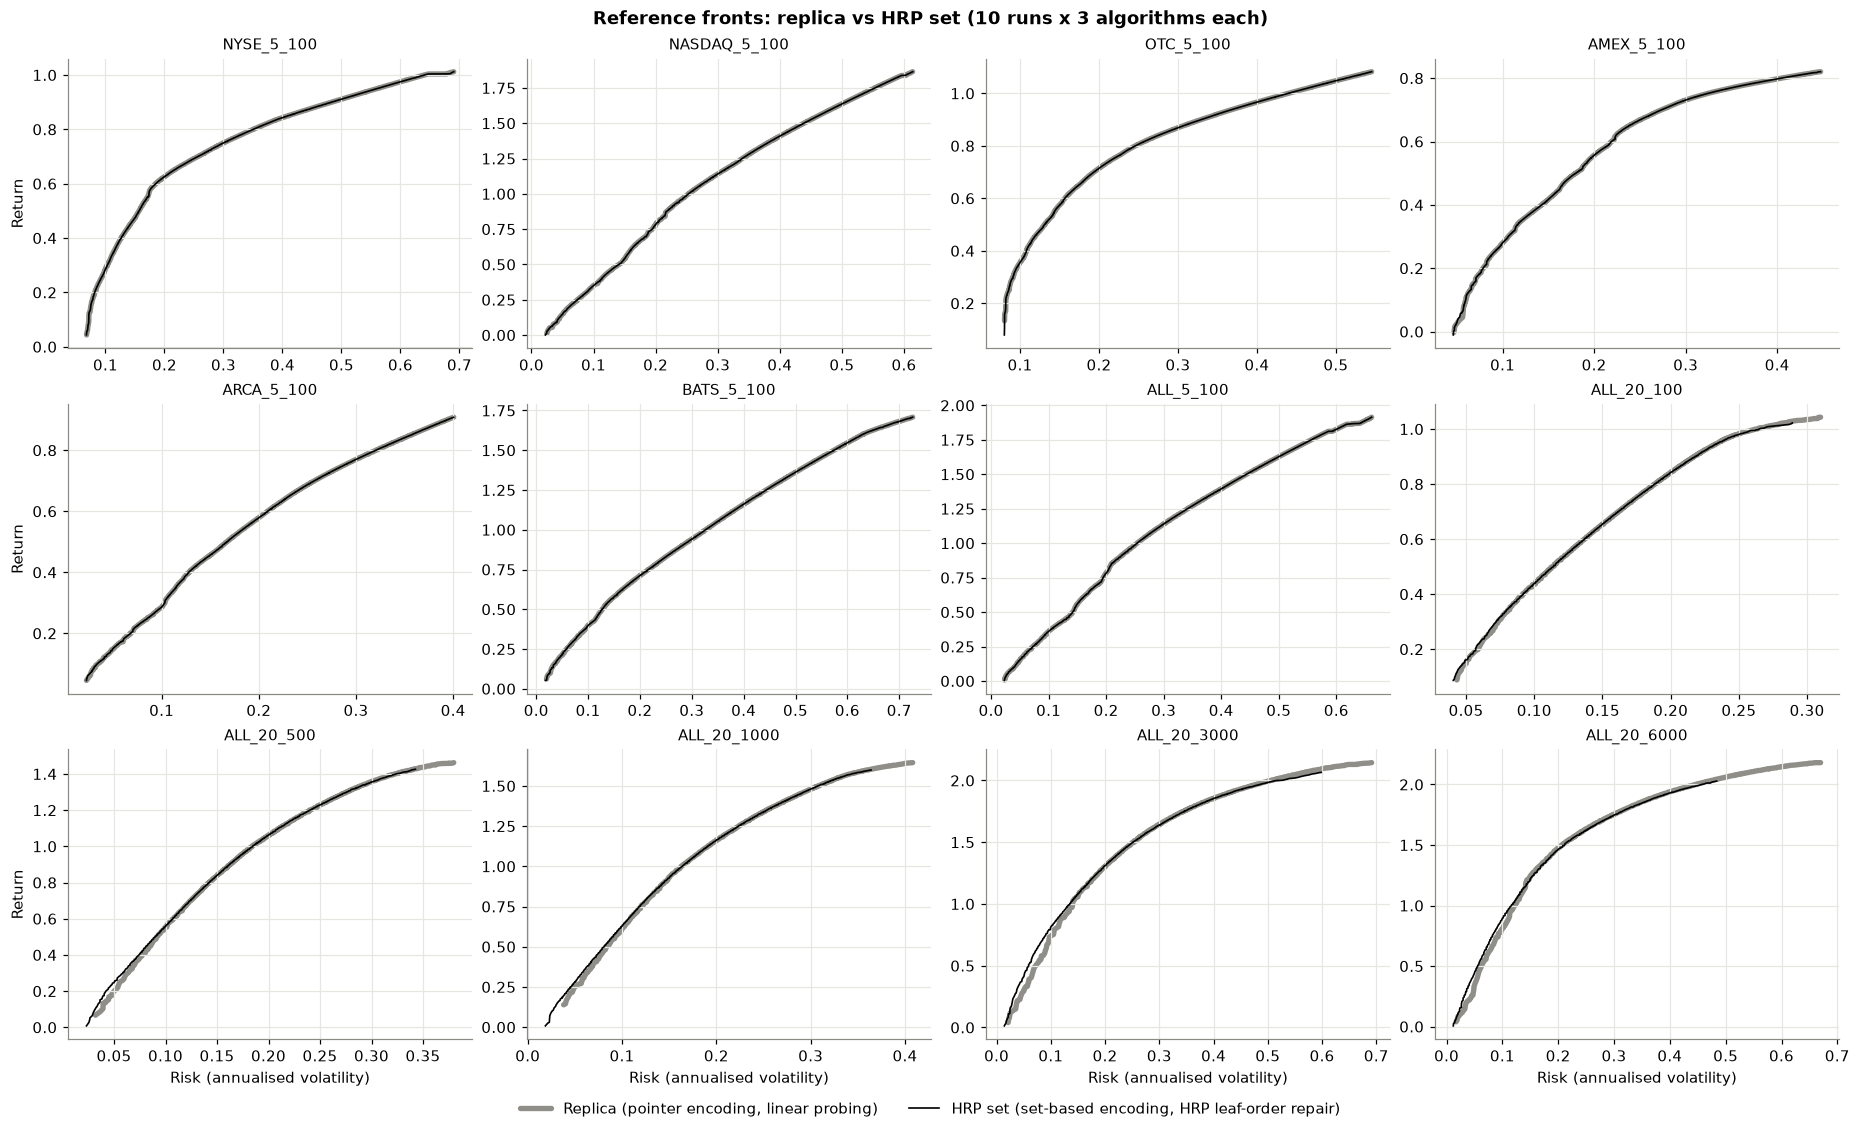

In [10]:
plot_reference_fronts(["replica", "hrp"], "pymoo_replica_vs_hrp_reference_fronts.png",
                      f"Reference fronts: replica vs HRP set ({N_RUNS} runs x 3 algorithms each)")

## 4. Hybrid: the metaheuristic picks the assets, quadratic programming picks the weights

The cardinality-constrained mean–variance problem is a mixed-integer QP (MIQP):

$$\min_{w,\,z}\;\gamma\,\sigma^2_{\text{ann}}(w) - \mu^\top w \quad\text{s.t.}\quad \textstyle\sum_i w_i = 1,\quad \tfrac{1}{2k}\, z_i \le w_i \le \tfrac{2}{k}\, z_i,\quad \sum_i z_i = k,\quad z \in \{0,1\}^N$$

In the hybrid, the metaheuristic decides the binary part $z$: it chooses which $k$ assets are held. It uses the HRP set encoding, operators and collision repair from section 3. With $z$ fixed, what is left of the MIQP is a convex QP in the $k$ held weights. That QP is solved exactly for every evaluated portfolio with `quadprog`, a Goldfarb–Idnani dual active-set solver.

**The trade-off gene.** A single QP gives one point on the efficient frontier of the chosen assets. Which point is set by one extra gene $t \in [0,1]$, through the risk aversion $\gamma = 10^{-2 + 6t}$. At $t = 0$ the QP essentially maximises return, and at $t = 1$ it essentially minimises risk. The genotype is $(a_1, \dots, a_k, t)$. $t$ gets SBX and polynomial mutation, and the assets get slot crossover, swap mutation and HRP repair. Every evaluated portfolio is therefore mean–variance efficient for its own assets.

**Numerics.** The data contains perfectly correlated pairs, such as a unit and its warrant, so some covariance blocks are singular. A ridge of $10^{-8} \times$ the largest diagonal entry keeps the QP strictly convex without visibly changing its solution. The check below compares `quadprog` with SciPy's SLSQP on random portfolios.

In [11]:
class HybridPortfolioProblem(SetPortfolioProblem):
    """Genes: k asset ids and the trade-off t; the weights are the exact QP solution for those assets."""

    def tail_bounds(self):
        return np.zeros(1), np.ones(1)

    def repair_tail(self, T):
        return np.clip(T, 0.0, 1.0)

    def weights(self, X):
        k = self.k
        A = X[:, :k].astype(int)
        gamma = 10.0 ** (LOG10_GAMMA[0] + (LOG10_GAMMA[1] - LOG10_GAMMA[0]) * X[:, k])
        # quadprog: minimise 1/2 w'Gw - a'w  s.t.  C'w >= b, the first constraint being an equality
        C = np.hstack([np.ones((k, 1)), np.eye(k), -np.eye(k)])
        b = np.r_[1.0, np.full(k, self.w_min), np.full(k, -self.w_max)]
        W = np.empty((len(X), k))
        for i in range(len(X)):
            G = (2 * gamma[i] * TRADING_DAYS) * self.cov[np.ix_(A[i], A[i])]
            G[np.diag_indices(k)] += 1e-8 * G.diagonal().max()
            W[i] = quadprog.solve_qp(G, self.mu[A[i]], C, b, 1)[0]
        return np.clip(W, self.w_min, self.w_max)


PROBLEMS["hybrid"] = HybridPortfolioProblem

# check against SciPy's SLSQP on random asset sets and trade-offs
rng = np.random.default_rng(0)
gaps = []
for inst in [pick("AMEX_5_100"), pick("ALL_20_100")]:
    d = load_instance(inst)
    hybrid = HybridPortfolioProblem(d["mu"], d["cov"], d["k"], leaf_order(inst))
    for _ in range(100):
        S, t = rng.choice(hybrid.n_assets, d["k"], replace=False), rng.random()
        w = hybrid.weights(np.r_[S, t][None, :].astype(float))[0]
        gamma, cov_S = 10 ** (LOG10_GAMMA[0] + (LOG10_GAMMA[1] - LOG10_GAMMA[0]) * t), TRADING_DAYS * d["cov"][np.ix_(S, S)]
        f = lambda v: gamma * v @ cov_S @ v - d["mu"][S] @ v
        ref = scipy_minimize(f, np.full(d["k"], 1 / d["k"]), method="SLSQP", bounds=[(hybrid.w_min, hybrid.w_max)] * d["k"],
                             constraints=[{"type": "eq", "fun": lambda v: v.sum() - 1}], options={"ftol": 1e-15, "maxiter": 1000})
        gaps.append((f(w) - ref.fun) / abs(ref.fun))
print(f"{len(gaps)} random QPs: largest relative objective gap quadprog - SLSQP = {max(gaps):.1e} "
      f"(<= 0 means quadprog is at least as good)")

200 random QPs: largest relative objective gap quadprog - SLSQP = 2.5e-10 (<= 0 means quadprog is at least as good)


In [12]:
run_variant("hybrid")

hybrid: 360 of 360 runs still to do


  10.5 min  ALL_20_6000   SMS-EMOA  done


  18.3 min  ALL_20_3000   SMS-EMOA  done


  25.7 min  ALL_20_6000   MOEA/D    done


  30.3 min  ALL_20_1000   SMS-EMOA  done


...

  66.5 min  AMEX_5_100    NSGA-II   done


  66.6 min  ARCA_5_100    NSGA-II   done


  66.7 min  BATS_5_100    NSGA-II   done


  66.8 min  ALL_5_100     NSGA-II   done


  67.0 min  ALL_20_100    NSGA-II   done
hybrid: all runs finished in 67.0 min


### Comparison: replica vs HRP set vs hybrid

The method is the same as before, now measured against the union of all three variants' reference fronts. ▲ / ▽ are again relative to the replica.

In [13]:
fronts["hybrid"] = load_fronts("hybrid")
ref_front["hybrid"] = {inst: nondominated(np.vstack([F for alg in ALGORITHMS for F in fronts["hybrid"][inst, alg]]))
                       for inst in INSTANCES}
VARIANTS = ["replica", "hrp", "hybrid"]
per_run_3, per_ref_3 = compare(VARIANTS)
display(comparison_table(per_run_3, per_ref_3, VARIANTS, "HV"))
display(comparison_table(per_run_3, per_ref_3, VARIANTS, "IGD+"))

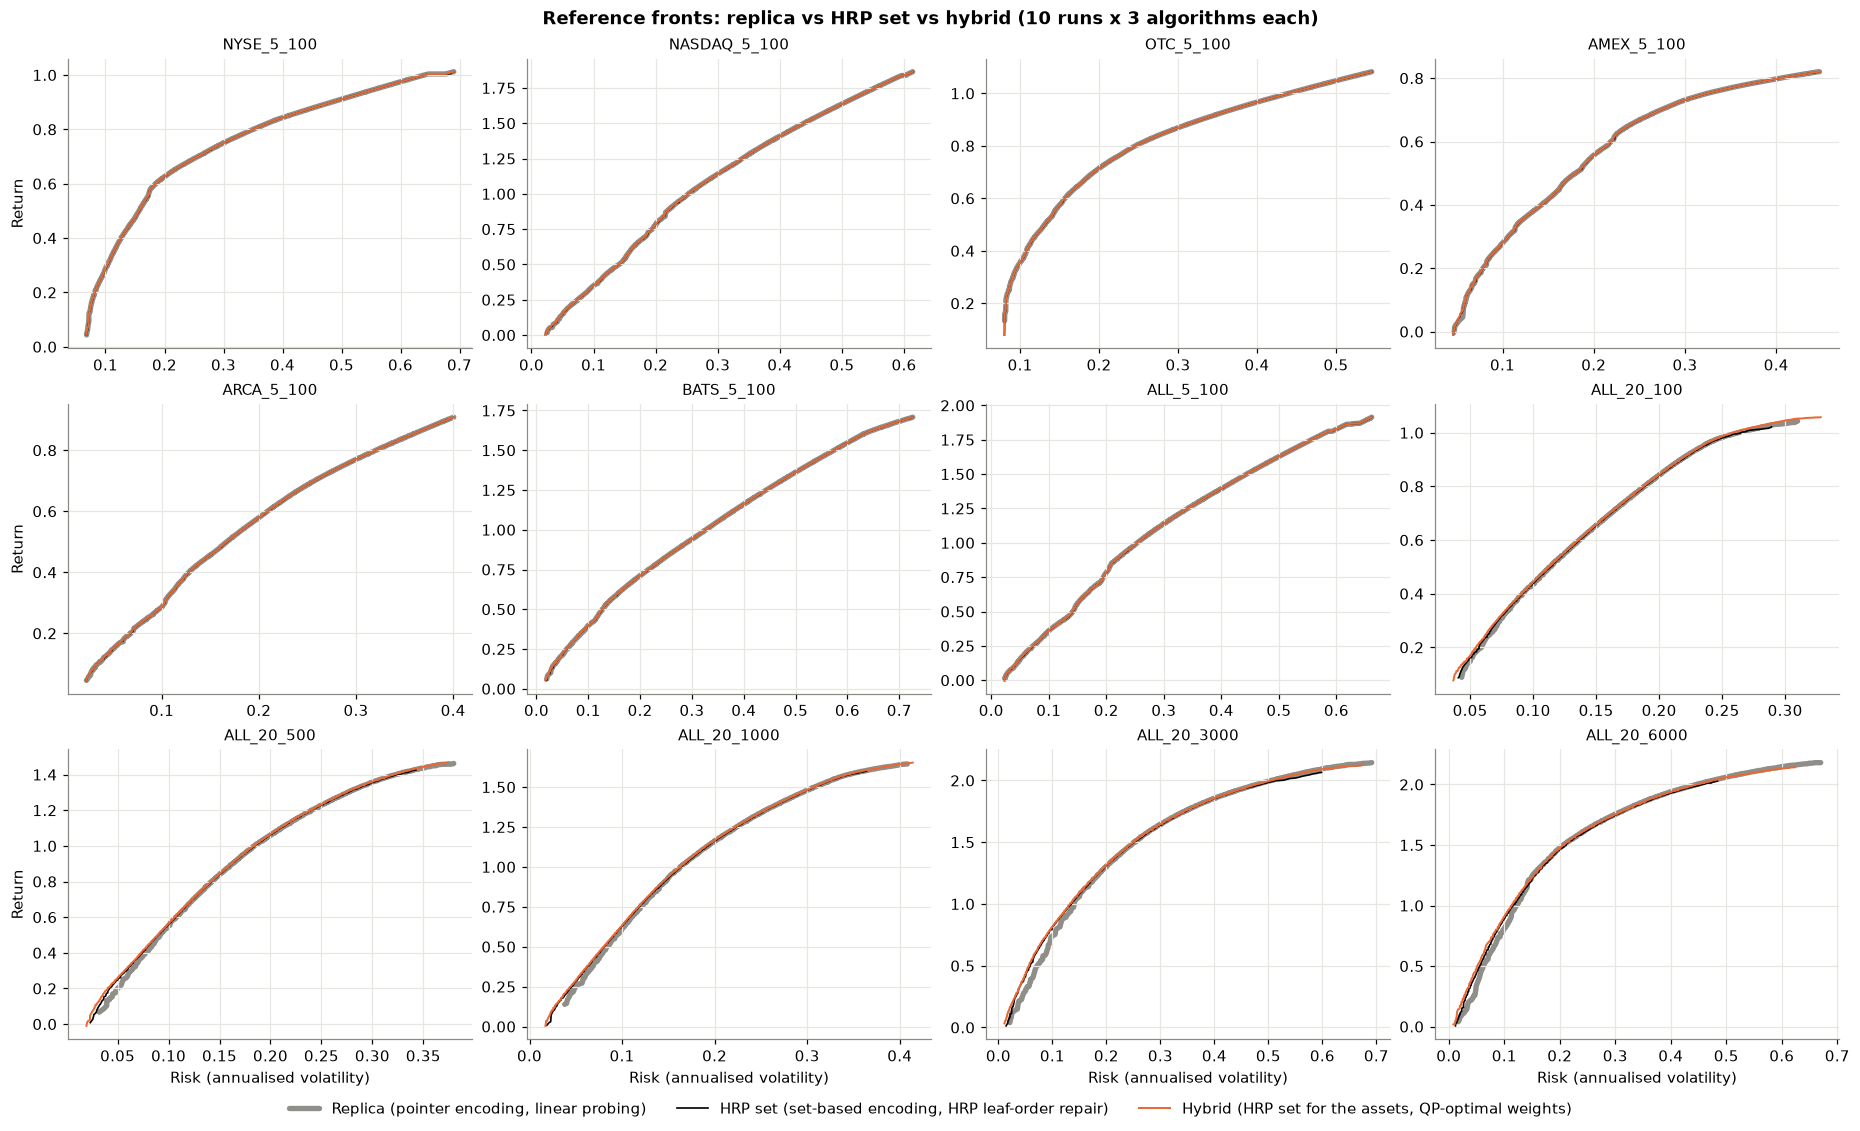

In [14]:
plot_reference_fronts(VARIANTS, "pymoo_replica_hrp_hybrid_reference_fronts.png",
                      f"Reference fronts: replica vs HRP set vs hybrid ({N_RUNS} runs x 3 algorithms each)")

**Best Sharpe ratio on each reference front**, $SR = (R - R_f)/\sigma$ with $R_f = 6.97\,\%$:

In [15]:
sharpe = pd.DataFrame({SHORT[v]: {inst: ((-ref_front[v][inst][:, 1] - RISK_FREE) / ref_front[v][inst][:, 0]).max()
                                  for inst in INSTANCES} for v in VARIANTS})
sharpe.style.format("{:.3f}").highlight_max(axis=1, props="background-color: #c8c7c1; color: #111") \
    .set_caption("Best Sharpe ratio on each variant's reference front")

,replica,HRP set,hybrid
NYSE_5_100,2.897,2.897,2.898
NASDAQ_5_100,3.714,3.714,3.715
OTC_5_100,3.387,3.388,3.388
AMEX_5_100,2.462,2.462,2.462
ARCA_5_100,2.598,2.597,2.598
BATS_5_100,3.433,3.435,3.438
ALL_5_100,3.737,3.736,3.737
ALL_20_100,3.907,3.907,3.921
ALL_20_500,5.149,5.144,5.152
ALL_20_1000,5.765,5.793,5.832


## 5. Summary

These results come from the default settings: 10 runs per algorithm and instance, seeds 12345–12354, and the same budgets as the replica. On a 6-core machine the HRP set runs took 65 min and the hybrid runs 67 min.

**HRP set vs replica: no overall gain.**
- **5-asset instances.** The merged reference fronts are practically identical, within 0.0005 HV of each other. Per run, the HRP set has significantly better HV on 8 of the 21 algorithm–instance pairs and worse on 1, mostly thanks to MOEA/D (better on 4 of 7).
- **20-asset instances.** The HRP set front is better at the low-risk end (below a risk of about 0.15) but does not reach the high-return end of the replica's front. Its merged front is better on ALL_20_500 and ALL_20_1000, equal on ALL_20_3000, and worse on ALL_20_100 and ALL_20_6000. Per run it is significantly worse on 11 of the 15 pairs and better on none.
- **A likely cause** of the missing high-return end: the replica's pointers index a universe sorted by return, so SBX and polynomial mutation move between assets with similar returns and can settle on the top of the list. Swap mutation instead draws a replacement uniformly from the whole universe (up to 6000 assets), which rarely hits the few best-return assets.
- **About the repair itself:** with single linkage, the next leaf is only moderately more correlated with the asset it replaces than the replica's next index (table in §2). For some assets it is not correlated at all, as for AIM in the example. Average or Ward linkage, or `linkage(..., optimal_ordering=True)`, would make leaf neighbours more similar.

**Hybrid: best on every instance.**
- **Reference fronts.** The hybrid's merged front has the best HV and the best IGD+ on all 12 instances.
- **Per run.** Its HV is significantly better than the replica's on 33 of the 36 algorithm–instance pairs and never significantly worse. The exceptions are SMS-EMOA on ALL_20_3000 and ALL_20_6000 and NSGA-II on ALL_20_6000.
- **Where the gain comes from.** It is largest on the 20-asset instances, where evolving 20 weights is hardest: the hybrid keeps the HRP set's better low-risk end and recovers the high-return end. On the 5-asset instances the three fronts nearly coincide, because 5 bounded weights are easy for evolution as well.
- **Sharpe ratio.** The best Sharpe ratio on the reference front rises from 7.94 (replica) and 8.35 (HRP set) to 8.95 (hybrid) on ALL_20_6000, and from 6.85 / 7.70 to 7.97 on ALL_20_3000. On the 5-asset instances all three agree to within 0.005.